# Local vs global model #
Material for the choice between one global model and one model per price area. The CNN in `neural_network.ipynb` is global: one network for all six locations, with location as a one-hot input. Here its trained convolutions are frozen and a new dense head (same layers as the CNN's head) is trained from scratch for each location on that location's rows only. The two are compared on the same test hours as the other models.

* **Global CNN**: the networks saved by `neural_network.ipynb`, unchanged.
* **Local heads**: the same convolutions, plus one head per location and seed network. The number of epochs per location is chosen by early stopping on the three validation windows; everything else (loss, optimizer, learning rate, batch size, dropout) is the global CNN's.

Requires `results/neural_network_models.pt`, which `neural_network.ipynb` writes. Takes a few minutes, as the heads train on the cached output of the convolutions.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from forecast_checks import LeakageChecker, ForecastValidator, MakeTrainingData, paired_bootstrap
from neural_network_helper import SEED, STATIC_COLS, WindowScaler, load_ensemble, ensemble_predict
from local_heads_helper import head_epochs, fit_local_heads, predict_local_heads

torch.manual_seed(SEED)
np.random.seed(SEED)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
AREAS = {"oslo": "NO1 Oslo", "stavanger": "NO2 Stavanger", "trondheim": "NO3 Trondheim", "tromsø": "NO4 Tromsø",
         "bergen": "NO5 Bergen", "helsingfors": "FI Helsingfors"}

In [2]:
#Same data, split, validation windows and test hours as neural_network.ipynb, so the saved networks see the same inputs
WINDOW_HOURS = 168
trainer = MakeTrainingData(window_hours=WINDOW_HOURS)
df = trainer.df
data = trainer.get_train_test()
train, test = (df.loc[data[part]["feature"].index] for part in ("train", "test"))
LeakageChecker.check_split(train["date"], test["date"])
folds = [(train.loc[fit], train.loc[val]) for fit, val in MakeTrainingData.validation_windows(train["date"])]

feats = ["location", "hour", "weekday", *STATIC_COLS, *trainer.consumption_window, *trainer.temperature_window]
LeakageChecker.check_feature_names(feats)
LOCATIONS = sorted(df["location"].unique())
scored = feats + ["consumption_6days_ago", "consumption_7days_ago", "consumption_14days_ago"]
train, test = (d.dropna(subset=scored) for d in (train, test))
folds = [(fit.dropna(subset=scored), val.dropna(subset=scored)) for fit, val in folds]


def make_scaler(data):
    return WindowScaler(data, trainer.consumption_window, trainer.temperature_window, LOCATIONS)

In [3]:
#The networks of neural_network.ipynb: the ensemble refitted on the whole training period, and one per validation window
saved = torch.load("results/neural_network_models.pt")
params = saved["params"]
scaler = make_scaler(train)
n_static = scaler.X(test.iloc[:1])[1].shape[1]
global_models = load_ensemble(saved["test"], params, WINDOW_HOURS, n_static)
fold_models = [load_ensemble(states, params, WINDOW_HOURS, n_static) for states in saved["folds"]]

#The loaded networks must give exactly the forecasts neural_network.ipynb saved, otherwise the inputs or scaling differ
global_pred = ensemble_predict(global_models, test, scaler)
saved_cnn = ForecastValidator.load_predictions("results/neural_network_predictions.json")
assert saved_cnn.actual.index.equals(test.index), "Not the test hours of neural_network.ipynb"
assert np.allclose(global_pred, saved_cnn.forecasts["Neural network"]), "Loaded networks do not reproduce the saved forecasts"
print(f"{len(global_models)} seed networks, {len(fold_models)} validation windows; params {params}")

5 seed networks, 3 validation windows; params {'n_conv': 1, 'channels': 16, 'kernel': 5, 'hidden': 32, 'dropout': 0.24128585103835348, 'lr': 0.0015164326104162194, 'weight_decay': 0.00013197716228885217, 'batch_size': 256}


In [4]:
#Number of epochs per location: early stopping of each head on each validation window, for each seed network.
#The test period is not used. The mean over windows and networks is used for the final heads
start = pd.Timestamp.now()
stopping = pd.concat([head_epochs(networks, fit, val, make_scaler(fit), params).assign(window=k)
                      for k, (networks, (fit, val)) in enumerate(zip(fold_models, folds))])
epochs = stopping.groupby("location")["epoch"].mean().round().astype(int).to_dict()
print(f"{(pd.Timestamp.now() - start).total_seconds():.0f} s; epochs per location: {epochs}")
stopping.pivot_table(index="location", columns="window", values="epoch", aggfunc="mean")

284 s; epochs per location: {'bergen': 24, 'helsingfors': 24, 'oslo': 45, 'stavanger': 33, 'tromsø': 18, 'trondheim': 37}


window,0,1,2
location,,,
bergen,27.0,31.4,13.0
helsingfors,24.8,23.4,23.4
oslo,53.6,39.8,41.4
stavanger,48.0,40.6,9.6
tromsø,26.0,11.2,17.6
trondheim,23.4,50.0,38.0


In [5]:
#Validation forecasts with those epochs, like the global CNN's in neural_network.ipynb (fitted up to 6 days before each
#window). The windows contain Christmas and New Year, which the test period does not. Note that the epochs were chosen
#on these windows, so the local heads' validation scores are slightly optimistic
val_global, val_local = [], []
for networks, (fit, val) in zip(fold_models, folds):
    fit_scaler = make_scaler(fit)
    val_global.append(ensemble_predict(networks, val, fit_scaler))
    val_local.append(predict_local_heads(networks, fit_local_heads(networks, fit, fit_scaler, params, epochs), val, fit_scaler))
val_all = pd.concat([val for _, val in folds])
val_validator = (ForecastValidator(val_all["consumption"], groups=val_all["location"])
                 .add("Same hour last week", val_all["consumption_7days_ago"], baseline=True)
                 .add("Global CNN", np.concatenate(val_global))
                 .add("Local heads", np.concatenate(val_local)))
val_validator.save_predictions("results/local_vs_global_validation_predictions.json")
val_validator.per_group(skill=True)

mae      rmse       nmae      bias  \
model               group                                                  
Same hour last week bergen       0.494656  0.571749  14.471781 -0.068834   
                    helsingfors  0.135916  0.178670   2.059390  0.007267   
                    oslo         2.342415  2.610506  17.462961 -0.188957   
                    stavanger    0.915348  1.048347  14.607397 -0.083916   
                    tromsø       0.187643  0.226556   9.280477 -0.027062   
                    trondheim    0.563126  0.654318  15.066702 -0.076558   
Global CNN          bergen       0.206187  0.254633   6.032244 -0.020471   
                    helsingfors  0.501085  0.597184   7.592423  0.072510   
                    oslo         0.716619  0.922817   5.342477  0.121461   
                    stavanger    0.393256  0.497254   6.275705 -0.142997   
                    tromsø       0.098536  0.121435   4.873422 -0.000173   
                    trondheim    0.203859  0.259171   5.454351 -0.014626   
Local heads         bergen       0.325975  0.433866   9.536808  0.127536   
                    helsingfors  0.226700  0.320266   3.434950  0.082731   
                    oslo         1.061996  1.350730   7.917297  0.045676   
                    stavanger    0.389378  0.503869   6.213809 -0.073704   
                    tromsø       0.124984  0.150678   6.181473 -0.065895   
                    trondheim    0.330768  0.386345   8.849850 -0.086418   

                                    skill  
model               group                  
Same hour last week bergen       0.000000  
                    helsingfors  0.000000  
                    oslo         0.000000  
                    stavanger    0.000000  
                    tromsø       0.000000  
                    trondheim    0.000000  
Global CNN          bergen       0.583172  
                    helsingfors -2.686734  
                    oslo         0.694068  
                    stavanger    0.570375  
                    tromsø       0.474874  
                    trondheim    0.637986  
Local heads         bergen       0.341007  
                    helsingfors -0.667945  
                    oslo         0.546623  
                    stavanger    0.574612  
                    tromsø       0.333927  
                    trondheim    0.412622

In [6]:
CHRISTMAS = ("2022-12-24", "2023-01-01")
period = (val_all["date"].between(*CHRISTMAS)
          .map({True: "Christmas and New Year (24 Dec - 1 Jan)", False: "Other validation days"}).rename("period"))
val_validator.per(period, skill=True)

mae  \
model               period                                              
Same hour last week Christmas and New Year (24 Dec - 1 Jan)  0.532187   
                    Other validation days                    0.838910   
Global CNN          Christmas and New Year (24 Dec - 1 Jan)  0.390095   
                    Other validation days                    0.343211   
Local heads         Christmas and New Year (24 Dec - 1 Jan)  0.444829   
                    Other validation days                    0.400459   

                                                                 rmse  \
model               period                                              
Same hour last week Christmas and New Year (24 Dec - 1 Jan)  0.881321   
                    Other validation days                    1.282444   
Global CNN          Christmas and New Year (24 Dec - 1 Jan)  0.533903   
                    Other validation days                    0.511983   
Local heads         Christmas and New Year (24 Dec - 1 Jan)  0.701122   
                    Other validation days                    0.636367   

                                                                  nmae  \
model               period                                               
Same hour last week Christmas and New Year (24 Dec - 1 Jan)   9.012042   
                    Other validation days                    14.193054   
Global CNN          Christmas and New Year (24 Dec - 1 Jan)   6.605860   
                    Other validation days                     5.806586   
Local heads         Christmas and New Year (24 Dec - 1 Jan)   7.532729   
                    Other validation days                     6.775138   

                                                                 bias  \
model               period                                              
Same hour last week Christmas and New Year (24 Dec - 1 Jan) -0.077304   
                    Other validation days                   -0.071839   
Global CNN          Christmas and New Year (24 Dec - 1 Jan) -0.178362   
                    Other validation days                    0.051975   
Local heads         Christmas and New Year (24 Dec - 1 Jan) -0.336389   
                    Other validation days                    0.098090   

                                                                skill  
model               period                                             
Same hour last week Christmas and New Year (24 Dec - 1 Jan)  0.000000  
                    Other validation days                    0.000000  
Global CNN          Christmas and New Year (24 Dec - 1 Jan)  0.266996  
                    Other validation days                    0.590885  
Local heads         Christmas and New Year (24 Dec - 1 Jan)  0.164148  
                    Other validation days                    0.522644

In [7]:
#Heads trained on the whole training period on top of the saved test networks, then the test period is predicted once
heads = fit_local_heads(global_models, train, scaler, params, epochs)
local_pred = predict_local_heads(global_models, heads, test, scaler)
validator = (ForecastValidator(test["consumption"], groups=test["location"])
             .add("Same hour last week", test["consumption_7days_ago"], baseline=True)
             .add("Global CNN", global_pred)
             .add("Local heads", local_pred))
validator.save_predictions("results/local_vs_global_predictions.json")
validator.summary(skill=True)

,mae,rmse,nmae,bias,skill
Same hour last week,0.494720,0.806999,8.983281,0.033943,0.000000
Global CNN,0.257013,0.378409,4.666918,-0.001522,0.480488
Local heads,0.295141,0.459356,5.359266,-0.180956,0.403418


In [8]:
validator.per_group(skill=True)

mae      rmse       nmae      bias  \
model               group                                                  
Same hour last week bergen       0.346885  0.419259  10.768142  0.052396   
                    helsingfors  0.136010  0.261839   2.120825  0.006952   
                    oslo         1.303123  1.679950  10.670598  0.067276   
                    stavanger    0.594432  0.743627  10.514005  0.053905   
                    tromsø       0.181393  0.226528   9.410661  0.002203   
                    trondheim    0.406683  0.486778  11.252339  0.020940   
Global CNN          bergen       0.160713  0.201953   4.988923 -0.030064   
                    helsingfors  0.224805  0.293809   3.505413 -0.051745   
                    oslo         0.577646  0.720396   4.730046  0.088083   
                    stavanger    0.306339  0.388387   5.418361 -0.064447   
                    tromsø       0.104660  0.126837   5.429734  0.013183   
                    trondheim    0.167933  0.214896   4.646458  0.035889   
Local heads         bergen       0.194343  0.236442   6.032889 -0.116622   
                    helsingfors  0.189048  0.248514   2.947855 -0.150057   
                    oslo         0.775495  0.965789   6.350125 -0.644535   
                    stavanger    0.289258  0.362816   5.116245  0.032647   
                    tromsø       0.117765  0.147738   6.109661 -0.076111   
                    trondheim    0.204999  0.249515   5.672016 -0.131079   

                                    skill  
model               group                  
Same hour last week bergen       0.000000  
                    helsingfors  0.000000  
                    oslo         0.000000  
                    stavanger    0.000000  
                    tromsø       0.000000  
                    trondheim    0.000000  
Global CNN          bergen       0.536696  
                    helsingfors -0.652853  
                    oslo         0.556722  
                    stavanger    0.484653  
                    tromsø       0.423023  
                    trondheim    0.587067  
Local heads         bergen       0.439746  
                    helsingfors -0.389957  
                    oslo         0.404895  
                    stavanger    0.513388  
                    tromsø       0.350772  
                    trondheim    0.495926

## Local heads relative to the global CNN ##
Skill = 1 - MAE of the local heads / MAE of the global CNN, per price area: above 0 means the local heads are better. The interval is a 95 % bootstrap interval of the MAE difference (local - global) over whole days, so a difference is only counted as real when the interval excludes 0.

In [9]:
vs_global = (ForecastValidator(test["consumption"], groups=test["location"].astype(str).map(AREAS).rename("Price area"))
             .add("Global CNN", global_pred, baseline=True)
             .add("Local heads", local_pred))
skill_vs_global = 100 * vs_global.per_group(skill=True).loc["Local heads", "skill"].reindex(AREAS.values())

#Per area and for all areas together
bootstrap = pd.concat([
    paired_bootstrap(vs_global.actual, vs_global.forecasts["Local heads"], vs_global.forecasts["Global CNN"],
                     test["date"], vs_global.groups).reindex(AREAS.values()),
    paired_bootstrap(vs_global.actual, vs_global.forecasts["Local heads"], vs_global.forecasts["Global CNN"],
                     test["date"], pd.Series("All", index=test.index, name="Price area"))])
overall_skill = 100 * vs_global.summary(skill=True).loc["Local heads", "skill"]
bootstrap.assign(skill_vs_global=pd.concat([skill_vs_global, pd.Series({"All": overall_skill})])).round(4)

,mae_difference,ci_low,ci_high,significant,skill_vs_global
Price area,,,,,
NO1 Oslo,0.1978,0.0987,0.3001,True,-34.2508
NO2 Stavanger,-0.0171,-0.0458,0.0111,False,5.5758
NO3 Trondheim,0.0371,0.0050,0.0661,True,-22.0718
NO4 Tromsø,0.0131,-0.0039,0.0297,False,-12.5223
NO5 Bergen,0.0336,0.0176,0.0503,True,-20.9257
FI Helsingfors,-0.0358,-0.0590,-0.0110,True,15.9056
All,0.0381,0.0159,0.0582,True,-14.8352


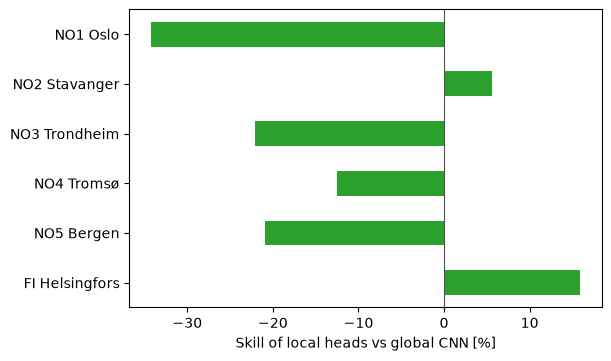

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
skill_vs_global[::-1].plot.barh(ax=ax, color=validator.colors(["Local heads"]))
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_xlabel("Skill of local heads vs global CNN [%]")
ax.set_ylabel("")
fig.savefig(FIGURES / "local_vs_global.pdf")

In [11]:
#Seed-to-seed spread: the test MAE of each seed network alone. A difference between the two variants that is smaller
#than this spread is within the noise of training
per_seed = pd.DataFrame({
    "Global CNN": [ForecastValidator.score(test["consumption"], ensemble_predict([model], test, scaler))["mae"]
                   for model in global_models],
    "Local heads": [ForecastValidator.score(test["consumption"], predict_local_heads([model], [head], test, scaler))["mae"]
                    for model, head in zip(global_models, heads)]}).rename_axis("seed network")
per_seed.describe().loc[["mean", "std", "min", "max"]]

,Global CNN,Local heads
mean,0.304411,0.346314
std,0.023620,0.086084
min,0.281659,0.283767
max,0.330857,0.495148


## Conclusion ##
Points for the report section *Models: one global model vs. one model per area*:

* **Accuracy**: the global CNN is better overall on the test period (MAE 0.257 vs 0.295 MW, bias -0.002 vs -0.181), and the difference is significant (bootstrap interval of the MAE difference 0.016 to 0.058). It is significantly better in Oslo, Trondheim and Bergen; the local heads are only significantly better in Helsingfors (MAE 0.189 vs 0.225), and Stavanger and Tromsø are within the noise. The seed spread agrees: every global seed network (MAE 0.28 to 0.33) is at least as good as the mean local head (0.35), and the local heads vary more between seeds (std 0.086 vs 0.024).
* **Helsingfors** is the weak area for both: the same-hour-last-week baseline (MAE 0.136) beats both variants there. A local head helps, but does not fix it.
* **Data per location**: each head learns from fewer than 6,000 training hours (Helsingfors fewer, as its series starts in July), against about 36,000 for the global model, so local models are more prone to overfitting. The larger bias of the local heads (Oslo -0.64 MW) fits this.
* **Holidays**: on the validation windows the global CNN is also better over Christmas and New Year (skill 27 % vs 16 % against the baseline).
* **Maintenance**: one model against six heads to retrain, monitor and version.
* **New areas or retailers**: a shared trunk can serve a new area with little history by training only a small head.
* **Portfolio level shifts** are per location; a local head can be retrained for one area without touching the others.

Note: an earlier run of this notebook showed the local heads 62 % better. That came from a global CNN with one collapsed seed network (constant forecast, learning rate about 0.01), not from the local heads; see `neural_network.ipynb`.